In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels as st
import sklearn as sk

In [2]:
churn_data = pd.read_csv('churn_data.csv')
internet_data = pd.read_csv('internet_data.csv')
customer_data = pd.read_csv('customer_data.csv')

In [3]:
churn_data.head()

,customerID,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,1,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,34,Yes,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,2,Yes,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,45,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,2,Yes,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
churn_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   tenure            7043 non-null   int64  
 2   PhoneService      7043 non-null   str    
 3   Contract          7043 non-null   str    
 4   PaperlessBilling  7043 non-null   str    
 5   PaymentMethod     7043 non-null   str    
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   str    
 8   Churn             7043 non-null   str    
dtypes: float64(1), int64(1), str(7)
memory usage: 863.4 KB


In [5]:
internet_data.head()

,customerID,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,No phone service,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,No,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,No,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,No phone service,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,No,Fiber optic,No,No,No,No,No,No


In [6]:
internet_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   customerID        7043 non-null   str  
 1   MultipleLines     7043 non-null   str  
 2   InternetService   7043 non-null   str  
 3   OnlineSecurity    7043 non-null   str  
 4   OnlineBackup      7043 non-null   str  
 5   DeviceProtection  7043 non-null   str  
 6   TechSupport       7043 non-null   str  
 7   StreamingTV       7043 non-null   str  
 8   StreamingMovies   7043 non-null   str  
dtypes: str(9)
memory usage: 882.0 KB


In [7]:
customer_data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No


In [8]:
customer_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerID     7043 non-null   str  
 1   gender         7043 non-null   str  
 2   SeniorCitizen  7043 non-null   int64
 3   Partner        7043 non-null   str  
 4   Dependents     7043 non-null   str  
dtypes: int64(1), str(4)
memory usage: 411.2 KB


In [9]:
print(churn_data.shape,'\n')
print(internet_data.shape,'\n')
print(customer_data.shape,'\n')

(7043, 9) 

(7043, 9) 

(7043, 5) 



In [10]:
# combining all data files into a single datframe
df1 = pd.merge(churn_data, internet_data, how='inner', on='customerID')
Telecom_data = pd.merge(df1, customer_data, how='inner', on='customerID')

In [11]:
Telecom_data.head()

,customerID,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,MultipleLines,...,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,1,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,No phone service,...,No,Yes,No,No,No,No,Female,0,Yes,No
1,5575-GNVDE,34,Yes,One year,No,Mailed check,56.95,1889.5,No,No,...,Yes,No,Yes,No,No,No,Male,0,No,No
2,3668-QPYBK,2,Yes,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,No,...,Yes,Yes,No,No,No,No,Male,0,No,No
3,7795-CFOCW,45,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,No phone service,...,Yes,No,Yes,Yes,No,No,Male,0,No,No
4,9237-HQITU,2,Yes,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,No,...,No,No,No,No,No,No,Female,0,No,No


In [12]:
Telecom_data.shape

(7043, 21)

In [13]:
Telecom_data.describe()

,tenure,MonthlyCharges,SeniorCitizen
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,0.162147
std,24.559481,30.090047,0.368612
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,0.000000
50%,29.000000,70.350000,0.000000
75%,55.000000,89.850000,0.000000
max,72.000000,118.750000,1.000000


In [14]:
Telecom_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   tenure            7043 non-null   int64  
 2   PhoneService      7043 non-null   str    
 3   Contract          7043 non-null   str    
 4   PaperlessBilling  7043 non-null   str    
 5   PaymentMethod     7043 non-null   str    
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   str    
 8   Churn             7043 non-null   str    
 9   MultipleLines     7043 non-null   str    
 10  InternetService   7043 non-null   str    
 11  OnlineSecurity    7043 non-null   str    
 12  OnlineBackup      7043 non-null   str    
 13  DeviceProtection  7043 non-null   str    
 14  TechSupport       7043 non-null   str    
 15  StreamingTV       7043 non-null   str    
 16  StreamingMovies   7043 non-null   str    
 17  gender

In [15]:
Telecom_data['TotalCharges'] = pd.to_numeric(Telecom_data['TotalCharges'], errors='coerce')

In [16]:
Telecom_data['TotalCharges'] = Telecom_data['TotalCharges'].astype(float)

In [17]:
Telecom_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   tenure            7043 non-null   int64  
 2   PhoneService      7043 non-null   str    
 3   Contract          7043 non-null   str    
 4   PaperlessBilling  7043 non-null   str    
 5   PaymentMethod     7043 non-null   str    
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7032 non-null   float64
 8   Churn             7043 non-null   str    
 9   MultipleLines     7043 non-null   str    
 10  InternetService   7043 non-null   str    
 11  OnlineSecurity    7043 non-null   str    
 12  OnlineBackup      7043 non-null   str    
 13  DeviceProtection  7043 non-null   str    
 14  TechSupport       7043 non-null   str    
 15  StreamingTV       7043 non-null   str    
 16  StreamingMovies   7043 non-null   str    
 17  gender

In [18]:
Telecom_data['OnlineSecurity'].value_counts()

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

In [19]:
# convert Yes/ No to 1 or 0 respectively throug all of the features
varlist = ['Partner','Dependents','PhoneService','PaperlessBilling','Churn']

def binary_map(x):
  return x.map({'Yes': 1, 'No': 0})

Telecom_data[varlist] = Telecom_data[varlist].apply(binary_map)

In [20]:
Telecom_data.head()

,customerID,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,MultipleLines,...,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,1,0,Month-to-month,1,Electronic check,29.85,29.85,0,No phone service,...,No,Yes,No,No,No,No,Female,0,1,0
1,5575-GNVDE,34,1,One year,0,Mailed check,56.95,1889.50,0,No,...,Yes,No,Yes,No,No,No,Male,0,0,0
2,3668-QPYBK,2,1,Month-to-month,1,Mailed check,53.85,108.15,1,No,...,Yes,Yes,No,No,No,No,Male,0,0,0
3,7795-CFOCW,45,0,One year,0,Bank transfer (automatic),42.30,1840.75,0,No phone service,...,Yes,No,Yes,Yes,No,No,Male,0,0,0
4,9237-HQITU,2,1,Month-to-month,1,Electronic check,70.70,151.65,1,No,...,No,No,No,No,No,No,Female,0,0,0


In [21]:
Telecom_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   tenure            7043 non-null   int64  
 2   PhoneService      7043 non-null   int64  
 3   Contract          7043 non-null   str    
 4   PaperlessBilling  7043 non-null   int64  
 5   PaymentMethod     7043 non-null   str    
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7032 non-null   float64
 8   Churn             7043 non-null   int64  
 9   MultipleLines     7043 non-null   str    
 10  InternetService   7043 non-null   str    
 11  OnlineSecurity    7043 non-null   str    
 12  OnlineBackup      7043 non-null   str    
 13  DeviceProtection  7043 non-null   str    
 14  TechSupport       7043 non-null   str    
 15  StreamingTV       7043 non-null   str    
 16  StreamingMovies   7043 non-null   str    
 17  gender

In [22]:
# get dummies across multiple values in features
stat = pd.get_dummies(Telecom_data[['gender','InternetService','Contract','PaymentMethod']], drop_first = True)
stat.head()

,gender_Male,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,False,False,False,False,False,False,True,False
1,True,False,False,True,False,False,False,True
2,True,False,False,False,False,False,False,True
3,True,False,False,True,False,False,False,False
4,False,True,False,False,False,False,True,False


In [23]:
stat.shape

(7043, 8)

In [24]:
Telecom_data = pd.concat([Telecom_data, stat], axis=1)
Telecom_data.head()

,customerID,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,MultipleLines,...,Partner,Dependents,gender_Male,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,7590-VHVEG,1,0,Month-to-month,1,Electronic check,29.85,29.85,0,No phone service,...,1,0,False,False,False,False,False,False,True,False
1,5575-GNVDE,34,1,One year,0,Mailed check,56.95,1889.50,0,No,...,0,0,True,False,False,True,False,False,False,True
2,3668-QPYBK,2,1,Month-to-month,1,Mailed check,53.85,108.15,1,No,...,0,0,True,False,False,False,False,False,False,True
3,7795-CFOCW,45,0,One year,0,Bank transfer (automatic),42.30,1840.75,0,No phone service,...,0,0,True,False,False,True,False,False,False,False
4,9237-HQITU,2,1,Month-to-month,1,Electronic check,70.70,151.65,1,No,...,0,0,False,True,False,False,False,False,True,False


In [25]:
Telecom_data.shape

(7043, 29)

In [26]:
Telecom_data = Telecom_data.drop(['gender','InternetService','Contract','PaymentMethod'], axis=1)
Telecom_data.head()

,customerID,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines,OnlineSecurity,OnlineBackup,...,Partner,Dependents,gender_Male,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,7590-VHVEG,1,0,1,29.85,29.85,0,No phone service,No,Yes,...,1,0,False,False,False,False,False,False,True,False
1,5575-GNVDE,34,1,0,56.95,1889.50,0,No,Yes,No,...,0,0,True,False,False,True,False,False,False,True
2,3668-QPYBK,2,1,1,53.85,108.15,1,No,Yes,Yes,...,0,0,True,False,False,False,False,False,False,True
3,7795-CFOCW,45,0,0,42.30,1840.75,0,No phone service,Yes,No,...,0,0,True,False,False,True,False,False,False,False
4,9237-HQITU,2,1,1,70.70,151.65,1,No,No,No,...,0,0,False,True,False,False,False,False,True,False


In [27]:
Telecom_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 25 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   customerID                             7043 non-null   str    
 1   tenure                                 7043 non-null   int64  
 2   PhoneService                           7043 non-null   int64  
 3   PaperlessBilling                       7043 non-null   int64  
 4   MonthlyCharges                         7043 non-null   float64
 5   TotalCharges                           7032 non-null   float64
 6   Churn                                  7043 non-null   int64  
 7   MultipleLines                          7043 non-null   str    
 8   OnlineSecurity                         7043 non-null   str    
 9   OnlineBackup                           7043 non-null   str    
 10  DeviceProtection                       7043 non-null   str    
 11  TechSupport    

In [28]:
# Creating dummy variables for the remaining categorical variables and dropping the levels with big names

# Creating the dummy variable for the variables 'MultipleLines'
ml = pd.get_dummies(Telecom_data['MultipleLines'], prefix = 'MultipleLines')
ml = ml.drop(['MultipleLines_No phone service'], axis = 1)
Telecom_data = pd.concat([Telecom_data, ml], axis = 1)

In [29]:
# Creating the dummy variables for the variable 'Online Security'
os = pd.get_dummies(Telecom_data['OnlineSecurity'], prefix = 'OnlineSecurity')
os = os.drop(['OnlineSecurity_No internet service'], axis = 1)
Telecom_data = pd.concat([Telecom_data, os], axis = 1)

In [30]:
# Creating the dummy variables for the variable 'Online Backup'
ob = pd.get_dummies(Telecom_data['OnlineBackup'], prefix = 'OnlineBackup')
ob = ob.drop(['OnlineBackup_No internet service'], axis = 1)
Telecom_data = pd.concat([Telecom_data, ob], axis = 1)

In [31]:
# Creating the dummy variables for the variable 'Device Protection'
dp = pd.get_dummies(Telecom_data['DeviceProtection'], prefix = 'DeviceProtection')
dp = dp.drop(['DeviceProtection_No internet service'], axis = 1)
Telecom_data = pd.concat([Telecom_data, dp], axis = 1)

In [32]:
# Creating the dummy variables for the variable 'tech Support'
ts = pd.get_dummies(Telecom_data['TechSupport'], prefix = 'TechSupport')
ts = ts.drop(['TechSupport_No internet service'], axis = 1)
Telecom_data = pd.concat([Telecom_data, ts], axis = 1)

In [33]:
# Creating the dummy variables for the variable 'Streaming TV'
st = pd.get_dummies(Telecom_data['StreamingTV'], prefix = 'StreamingTV')
st = st.drop(['StreamingTV_No internet service'], axis = 1)
Telecom_data = pd.concat([Telecom_data, st], axis = 1)

In [34]:
# Creating the dummy variables for the variable 'Streaming Movies'
sm = pd.get_dummies(Telecom_data['StreamingMovies'], prefix = 'StreamingMovies')
sm = sm.drop(['StreamingMovies_No internet service'], axis = 1)
Telecom_data = pd.concat([Telecom_data, sm], axis = 1)

In [35]:
Telecom_data.shape

(7043, 39)

In [36]:
telecom = Telecom_data.drop(['MultipleLines','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies'], axis=1)
telecom.head()

,customerID,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,SeniorCitizen,Partner,Dependents,...,OnlineBackup_No,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_Yes,TechSupport_No,TechSupport_Yes,StreamingTV_No,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_Yes
0,7590-VHVEG,1,0,1,29.85,29.85,0,0,1,0,...,False,True,True,False,True,False,True,False,True,False
1,5575-GNVDE,34,1,0,56.95,1889.50,0,0,0,0,...,True,False,False,True,True,False,True,False,True,False
2,3668-QPYBK,2,1,1,53.85,108.15,1,0,0,0,...,False,True,True,False,True,False,True,False,True,False
3,7795-CFOCW,45,0,0,42.30,1840.75,0,0,0,0,...,True,False,False,True,False,True,True,False,True,False
4,9237-HQITU,2,1,1,70.70,151.65,1,0,0,0,...,True,False,True,False,True,False,True,False,True,False


In [37]:
telecom.shape

(7043, 32)

In [38]:
telecom['TotalCharges'] = pd.to_numeric(telecom['TotalCharges'], errors='coerce')

In [39]:
telecom['TotalCharges'].isnull().sum()

np.int64(11)

In [40]:
telecom.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 32 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   customerID                             7043 non-null   str    
 1   tenure                                 7043 non-null   int64  
 2   PhoneService                           7043 non-null   int64  
 3   PaperlessBilling                       7043 non-null   int64  
 4   MonthlyCharges                         7043 non-null   float64
 5   TotalCharges                           7032 non-null   float64
 6   Churn                                  7043 non-null   int64  
 7   SeniorCitizen                          7043 non-null   int64  
 8   Partner                                7043 non-null   int64  
 9   Dependents                             7043 non-null   int64  
 10  gender_Male                            7043 non-null   bool   
 11  InternetService

In [41]:
telecom = telecom.dropna()

In [42]:
telecom.info()

<class 'pandas.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 32 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   customerID                             7032 non-null   str    
 1   tenure                                 7032 non-null   int64  
 2   PhoneService                           7032 non-null   int64  
 3   PaperlessBilling                       7032 non-null   int64  
 4   MonthlyCharges                         7032 non-null   float64
 5   TotalCharges                           7032 non-null   float64
 6   Churn                                  7032 non-null   int64  
 7   SeniorCitizen                          7032 non-null   int64  
 8   Partner                                7032 non-null   int64  
 9   Dependents                             7032 non-null   int64  
 10  gender_Male                            7032 non-null   bool   
 11  InternetService_Fibe

In [43]:
# check for outliers
num_telecom = telecom[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']]

In [44]:
num_telecom.describe(percentiles = [0.25, 0.5, 0.75, 0.90, 0.99])

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen
count,7032.000000,7032.000000,7032.000000,7032.000000
mean,32.421786,64.798208,2283.300441,0.162400
std,24.545260,30.085974,2266.771362,0.368844
min,1.000000,18.250000,18.800000,0.000000
25%,9.000000,35.587500,401.450000,0.000000
50%,29.000000,70.350000,1397.475000,0.000000
75%,55.000000,89.862500,3794.737500,0.000000
90%,69.000000,102.645000,5976.640000,1.000000
99%,72.000000,114.734500,8039.883000,1.000000
max,72.000000,118.750000,8684.800000,1.000000


In [45]:
import plotly.express as px
px.box(num_telecom, y='tenure')

In [46]:
px.box(num_telecom, y='MonthlyCharges')

In [47]:
px.box(num_telecom, y='TotalCharges')

<Axes: xlabel='customerID', ylabel='Churn'>

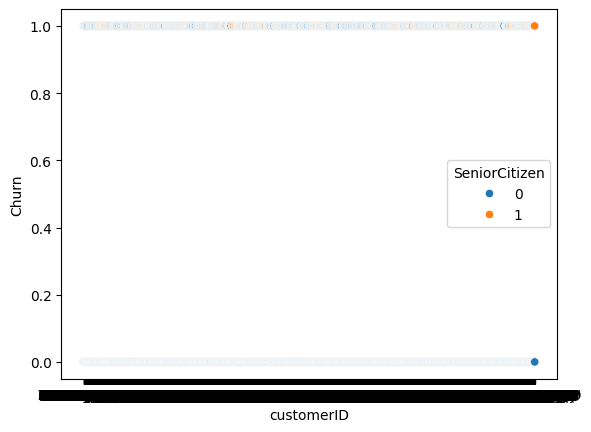

In [48]:
sns.scatterplot(data = telecom, x='customerID', y='Churn', hue = 'SeniorCitizen')

In [49]:
telecom.shape

(7032, 32)

# Step 4: Train Test Split

In [50]:
X = telecom.drop(['Churn', 'customerID'], axis=1)       # whenever a categorical problem is taken into consideration no feature having unique values or primary key canbe taken into feature set, i.e. why we are dropping customer id
y = telecom['Churn']

In [51]:
from sklearn.model_selection import train_test_split

In [52]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=100)

# Step 5: Feature Scaling
whenever we do Classification problem we always do Feature Scaling

In [53]:

from sklearn.preprocessing import StandardScaler

In [54]:
scaler = StandardScaler()
X_train[['tenure', 'MonthlyCharges', 'TotalCharges']] = scaler.fit_transform(X_train[['tenure', 'MonthlyCharges', 'TotalCharges']])

In [55]:
X_train.head()

,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,gender_Male,InternetService_Fiber optic,...,OnlineBackup_No,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_Yes,TechSupport_No,TechSupport_Yes,StreamingTV_No,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_Yes
879,0.019693,1,1,-0.338074,-0.276449,0,0,0,True,False,...,False,True,True,False,True,False,True,False,True,False
5790,0.305384,0,1,-0.464443,-0.112702,0,1,1,False,False,...,False,True,True,False,True,False,False,True,False,True
6498,-1.286319,1,1,0.581425,-0.974430,0,0,0,False,True,...,False,True,False,True,True,False,True,False,True,False
880,-0.919003,1,1,1.505913,-0.550676,0,0,0,True,True,...,False,True,False,True,False,True,False,True,False,True
2784,-1.163880,1,1,1.106854,-0.835971,0,0,1,False,True,...,True,False,False,True,False,True,False,True,False,True


In [56]:
# Check the Churn Rate for the outpur column
churn = (sum(telecom['Churn'])/len(telecom))*100
churn

26.578498293515356

# Step 6: Feature Engineering

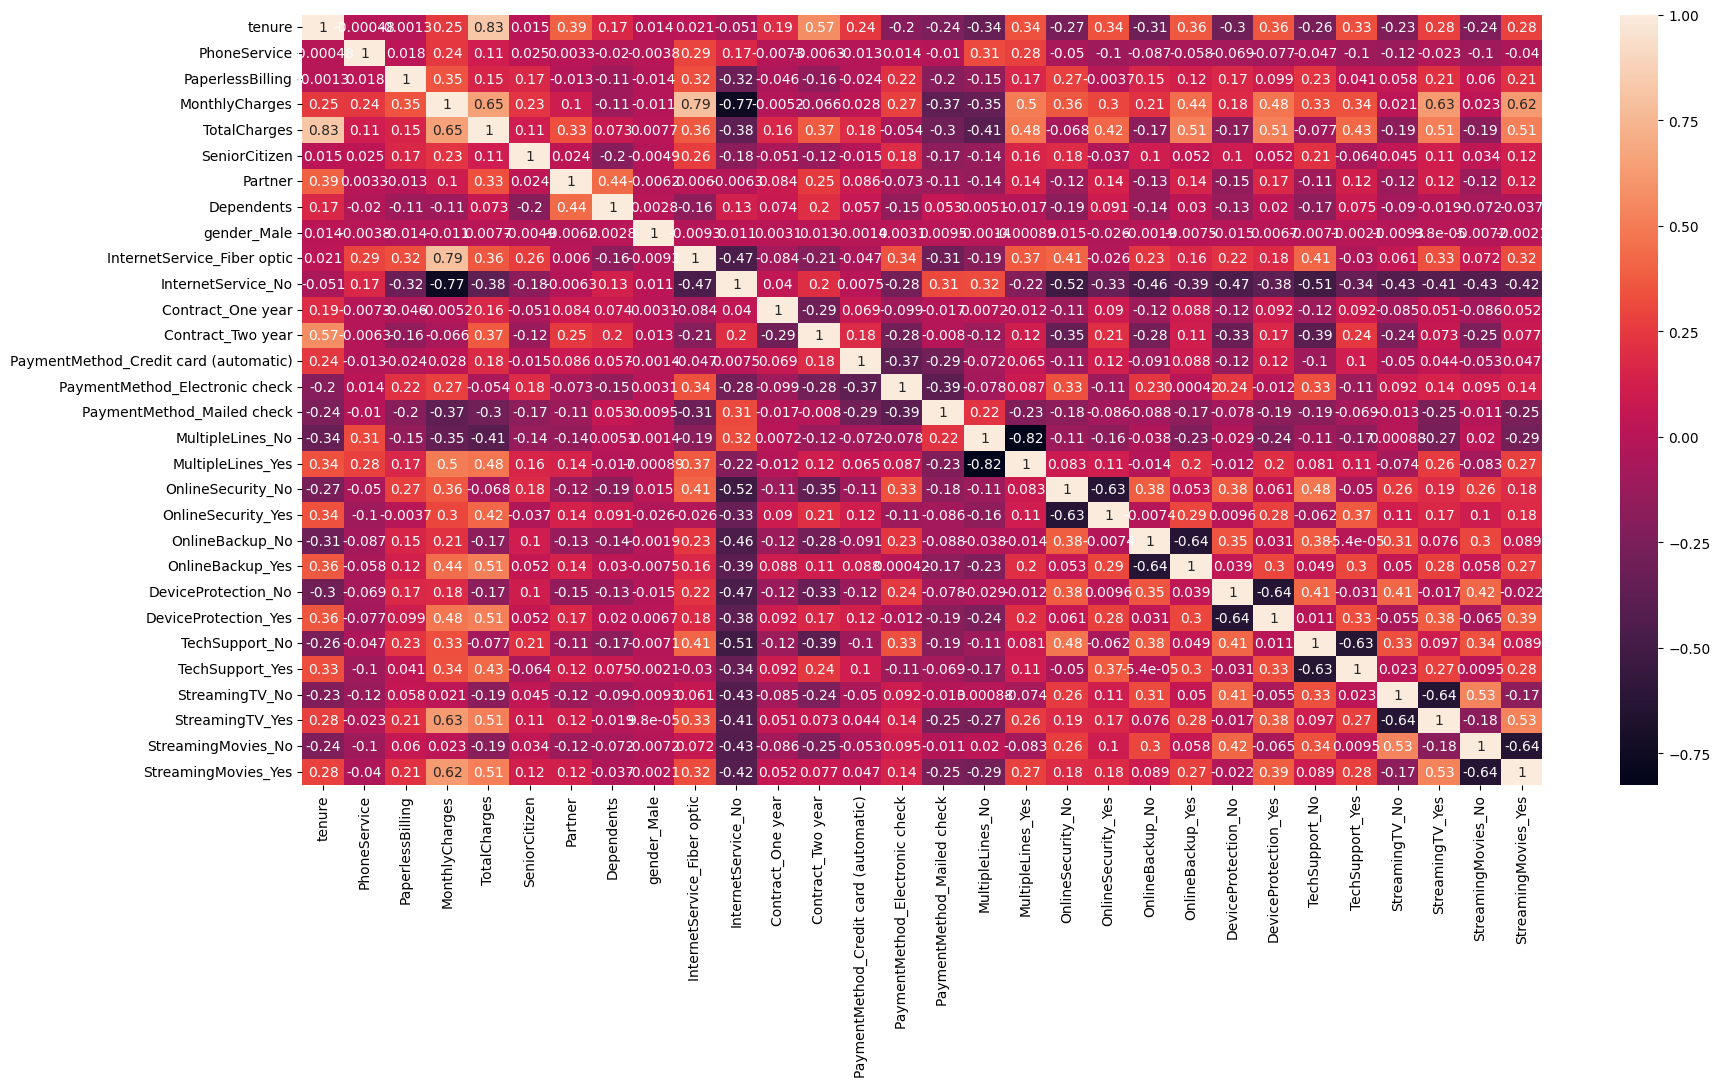

In [57]:
# plot heatmap across all of the features
plt.figure(figsize = (20,10))
sns.heatmap(X_train.corr(), annot = True)
plt.show()

In [58]:
X_test = X_test.drop([
    'MultipleLines_No',
    'OnlineSecurity_No',
    'OnlineBackup_No',
    'DeviceProtection_No',
    'TechSupport_No',
    'StreamingTV_No',
    'StreamingMovies_No'
], axis = 1)

In [59]:
X_train = X_train.drop([
    'MultipleLines_No',
    'OnlineSecurity_No',
    'OnlineBackup_No',
    'DeviceProtection_No',
    'TechSupport_No',
    'StreamingTV_No',
    'StreamingMovies_No'
], axis = 1
)

# Step 7: Model Building

In [60]:
import statsmodels.api as sm

In [61]:
m1 = sm.GLM(y_train, (sm.add_constant(X_train)), family=sm.families.Binomial())
m1.fit().summary()

ValueError: Pandas data cast to numpy dtype of object. Check input data with np.asarray(data).

In [62]:
X_train_float = X_train.astype(float)
y_train_float = y_train.astype(float)

m1 = sm.GLM(
    y_train_float,
    sm.add_constant(X_train_float),
    family=sm.families.Binomial()
).fit()

m1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                  Churn   No. Observations:                 4922
Model:                            GLM   Df Residuals:                     4898
Model Family:                Binomial   Df Model:                           23
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2004.7
Date:                Tue, 27 Oct 2026   Deviance:                       4009.4
Time:                        11:49:56   Pearson chi2:                 6.07e+03
No. Iterations:                     7   Pseudo R-squ. (CS):             0.2844
Covariance Type:            nonrobust                                         
=========================================================================================================
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                    -3.9382      1.546     -2.547      0.011      -6.969      -0.908
tenure                                   -1.5172      0.189     -8.015      0.000      -1.888      -1.146
PhoneService                              0.9507      0.789      1.205      0.228      -0.595       2.497
PaperlessBilling                          0.3254      0.090      3.614      0.000       0.149       0.502
MonthlyCharges                           -2.1806      1.160     -1.880      0.060      -4.454       0.092
TotalCharges                              0.7332      0.198      3.705      0.000       0.345       1.121
SeniorCitizen                             0.3984      0.102      3.924      0.000       0.199       0.597
Partner                                   0.0374      0.094      0.399      0.690      -0.146       0.221
Dependents                               -0.1430      0.107     -1.332      0.183      -0.353       0.067
gender_Male                              -0.0346      0.078     -0.442      0.658      -0.188       0.119
InternetService_Fiber optic               2.5124      0.967      2.599      0.009       0.618       4.407
InternetService_No                       -2.7792      0.982     -2.831      0.005      -4.703      -0.855
Contract_One year                        -0.6578      0.129     -5.106      0.000      -0.910      -0.405
Contract_Two year                        -1.2455      0.212     -5.874      0.000      -1.661      -0.830
PaymentMethod_Credit card (automatic)    -0.2577      0.137     -1.883      0.060      -0.526       0.011
PaymentMethod_Electronic check            0.1615      0.113      1.434      0.152      -0.059       0.382
PaymentMethod_Mailed check               -0.2536      0.137     -1.845      0.065      -0.523       0.016
MultipleLines_Yes                         0.5623      0.214      2.628      0.009       0.143       0.982
OnlineSecurity_Yes                       -0.0245      0.216     -0.113      0.910      -0.448       0.399
OnlineBackup_Yes                          0.1740      0.212      0.822      0.411      -0.241       0.589
DeviceProtection_Yes                      0.3229      0.215      1.501      0.133      -0.099       0.744
TechSupport_Yes                          -0.0305      0.216     -0.141      0.888      -0.455       0.394
StreamingTV_Yes                           0.9598      0.396      2.423      0.015       0.183       1.736
StreamingMovies_Yes                       0.8484      0.396      2.143      0.032       0.072       1.624
=========================================================================================================
"""

In [63]:
# Removing the columns with p value too great than 0.05
X_test = X_test.drop([
    'Partner',
    'Dependents',
    'PhoneService',
    'gender_Male',
    'PaymentMethod_Electronic check',
    'OnlineSecurity_Yes',
    'OnlineBackup_Yes',
    'DeviceProtection_Yes',
    'TechSupport_Yes'
], axis = 1)

In [64]:
X_train = X_train.drop([
    'Partner',
    'Dependents',
    'PhoneService',
    'gender_Male',
    'PaymentMethod_Electronic check',
    'OnlineSecurity_Yes',
    'OnlineBackup_Yes',
    'DeviceProtection_Yes',
    'TechSupport_Yes'
], axis = 1)

In [65]:
X_train.shape

(4922, 14)

In [66]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression()

In [70]:
from sklearn.feature_selection import RFE       # Redundant Feature Elimination
                                                # A automatic feature selectyion process
rfe = RFE(estimator=logreg, n_features_to_select=10)                           # Model, how many features do you want in your model
rfe = rfe.fit(X_train, y_train)

In [ ]:
rfe.support_            # gives the boolean values for the features which are selected and which are not selected
                        # True for features which are selected and False for features which are not selected

array([ True, False,  True,  True,  True,  True,  True,  True,  True,
       False, False, False,  True,  True])

In [71]:
col = X_train.columns[rfe.support_]
col

Index(['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen',
       'InternetService_Fiber optic', 'InternetService_No',
       'Contract_One year', 'Contract_Two year', 'StreamingTV_Yes',
       'StreamingMovies_Yes'],
      dtype='str')

In [ ]:
list(zip(X_train.columns, rfe.support_, rfe.ranking_))
# rfe ranking states all 1 are the kept features and the rest are dropped. The ranking is based on the importance of the features in the model.

[('tenure', np.True_, np.int64(1)),
 ('PaperlessBilling', np.False_, np.int64(5)),
 ('MonthlyCharges', np.True_, np.int64(1)),
 ('TotalCharges', np.True_, np.int64(1)),
 ('SeniorCitizen', np.True_, np.int64(1)),
 ('InternetService_Fiber optic', np.True_, np.int64(1)),
 ('InternetService_No', np.True_, np.int64(1)),
 ('Contract_One year', np.True_, np.int64(1)),
 ('Contract_Two year', np.True_, np.int64(1)),
 ('PaymentMethod_Credit card (automatic)', np.False_, np.int64(4)),
 ('PaymentMethod_Mailed check', np.False_, np.int64(3)),
 ('MultipleLines_Yes', np.False_, np.int64(2)),
 ('StreamingTV_Yes', np.True_, np.int64(1)),
 ('StreamingMovies_Yes', np.True_, np.int64(1))]

In [73]:
X_train.columns

Index(['tenure', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'SeniorCitizen', 'InternetService_Fiber optic', 'InternetService_No',
       'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Mailed check',
       'MultipleLines_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes'],
      dtype='str')

# Assessing the Model with Stats Model Again

In [76]:
X_train_sm = sm.add_constant(X_train[col])
X_train_sm_float = X_train_sm.astype(float)
y_train_float = y_train.astype(float)

logm2 = sm.GLM(
    y_train_float,
    sm.add_constant(X_train_sm_float),
    family=sm.families.Binomial()
).fit()
res = logm2
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                  Churn   No. Observations:                 4922
Model:                            GLM   Df Residuals:                     4911
Model Family:                Binomial   Df Model:                           10
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2041.2
Date:                Tue, 27 Oct 2026   Deviance:                       4082.5
Time:                        12:04:16   Pearson chi2:                 6.22e+03
No. Iterations:                     7   Pseudo R-squ. (CS):             0.2737
Covariance Type:            nonrobust                                         
===============================================================================================
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                          -2.1157      0.139    -15.224      0.000      -2.388      -1.843
tenure                         -1.4312      0.183     -7.817      0.000      -1.790      -1.072
MonthlyCharges                 -0.8497      0.170     -5.001      0.000      -1.183      -0.517
TotalCharges                    0.6719      0.195      3.451      0.001       0.290       1.053
SeniorCitizen                   0.5246      0.098      5.358      0.000       0.333       0.717
InternetService_Fiber optic     1.7387      0.190      9.134      0.000       1.366       2.112
InternetService_No             -1.6731      0.204     -8.205      0.000      -2.073      -1.273
Contract_One year              -0.8254      0.126     -6.568      0.000      -1.072      -0.579
Contract_Two year              -1.5354      0.207     -7.421      0.000      -1.941      -1.130
StreamingTV_Yes                 0.5846      0.109      5.386      0.000       0.372       0.797
StreamingMovies_Yes             0.4719      0.107      4.427      0.000       0.263       0.681
===============================================================================================
"""

In [77]:
y_train_pred = res.predict(X_train_sm.astype(float))
y_train_pred

879     0.114824
5790    0.235517
6498    0.578150
880     0.585423
2784    0.699087
          ...   
79      0.010330
3934    0.184088
5964    0.058691
6947    0.128340
5649    0.045966
Length: 4922, dtype: float64

In [78]:
y_train_pred = y_train_pred.values.reshape(-1)
y_train_pred[:10]

array([0.11482365, 0.23551671, 0.57814993, 0.58542298, 0.69908704,
       0.33055784, 0.46896244, 0.7317239 , 0.16706547, 0.50138234])

In [79]:
y_train_pred_final = pd.DataFrame({'Churn':y_train.values, 'Churn_Prob':y_train_pred})
y_train_pred_final['CustID'] = y_train.index
y_train_pred_final.head()

,Churn,Churn_Prob,CustID
0,0,0.114824,879
1,0,0.235517,5790
2,1,0.578150,6498
3,1,0.585423,880
4,1,0.699087,2784


In [80]:
y_train_pred_final['predicted'] = y_train_pred_final.Churn_Prob.map(lambda x: 1 if x > 0.5 else 0)
y_train_pred_final.head()

,Churn,Churn_Prob,CustID,predicted
0,0,0.114824,879,0
1,0,0.235517,5790,0
2,1,0.578150,6498,1
3,1,0.585423,880,1
4,1,0.699087,2784,1


In [81]:
from sklearn import metrics

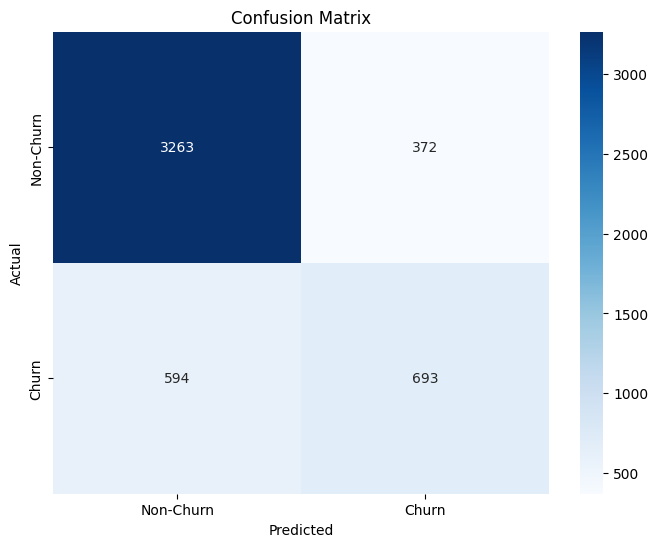

In [84]:
confusion = metrics.confusion_matrix(y_train_pred_final.Churn, y_train_pred_final.predicted)
confusion

# Visualizing the confusion matrix

plt.figure(figsize=(8, 6))
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Churn', 'Churn'], yticklabels=['Non-Churn', 'Churn'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [85]:
print(metrics.classification_report(y_train_pred_final.Churn, y_train_pred_final.predicted))

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      3635
           1       0.65      0.54      0.59      1287

    accuracy                           0.80      4922
   macro avg       0.75      0.72      0.73      4922
weighted avg       0.79      0.80      0.80      4922



- precision is Tp/(Tp + Fp)
-- i.e. when we say "this person will churn", we are right 65% of the time.

- recall(sensitivity) is Tp/(Tp + Fn)
-- i.e. when a person actually churns, we only caught 54%.

- Specificity is Tn/(Tn + Fp)
-- i.e. when a person actually does not churn, we caught 90% of the time.

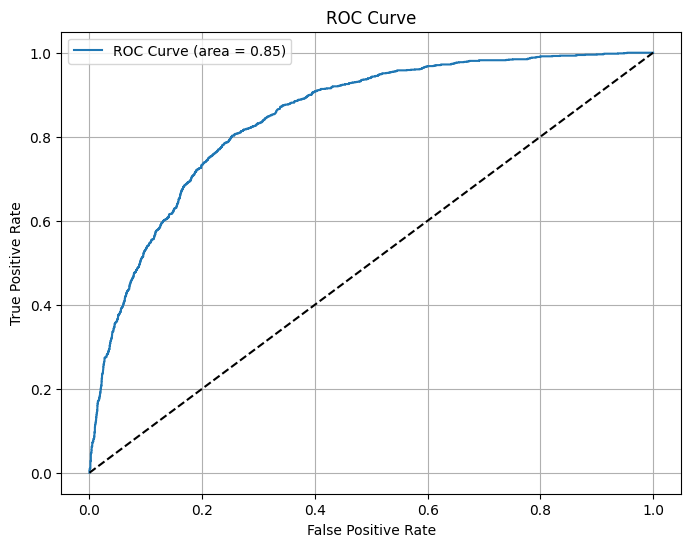

In [93]:
# ROC curve by calculating the values at different cutoffs
plt.figure(figsize=(8, 6))
fpr, tpr, thresholds = metrics.roc_curve(y_train_pred_final.Churn, y_train_pred_final.Churn_Prob, drop_intermediate=False)
plt.plot(fpr, tpr, label='ROC Curve (area = %0.2f)' % metrics.auc(fpr, tpr))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid()
plt.show()

In [100]:
# Let's calculate Accuracy, Sensitivity, and Specificity for various probability cutoffs

# Let's calculate Accuracy, Sensitivity, and Specificity for various probability cutoffs
cutoff_df = pd.DataFrame(columns=['prob', 'accuracy', 'sensi', 'speci'])

# Probability thresholds from 0.0 to 0.9 with step 0.1
numbers = [float(x)/10 for x in range(10)]

for i in numbers:
    # Predict Churn based on current threshold
    y_pred = y_train_pred_final.Churn_Prob.map(lambda x: 1 if x > i else 0)
    cm = metrics.confusion_matrix(y_train_pred_final.Churn, y_pred)
    
    total = sum(sum(cm))
    accuracy = (cm[0,0] + cm[1,1]) / total
    speci = cm[0,0] / (cm[0,0] + cm[0,1])
    sensi = cm[1,1] / (cm[1,0] + cm[1,1])
    
    cutoff_df.loc[i] = [i, accuracy, sensi, speci]

display(cutoff_df)

,prob,accuracy,sensi,speci
0.0,0.0,0.261479,1.000000,0.000000
0.1,0.1,0.608492,0.944833,0.489409
0.2,0.2,0.712922,0.874903,0.655571
0.3,0.3,0.766558,0.783994,0.760385
0.4,0.4,0.792361,0.661228,0.838790
0.5,0.5,0.803738,0.538462,0.897662
0.6,0.6,0.798659,0.376845,0.948006
0.7,0.7,0.768590,0.154623,0.985970
0.8,0.8,0.741162,0.014763,0.998349
0.9,0.9,0.738521,0.000000,1.000000


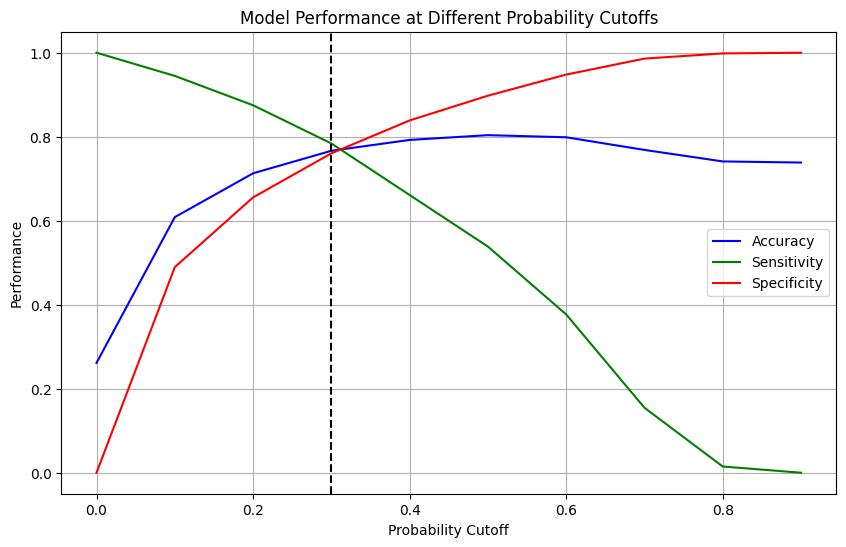

In [105]:
# Plotting Accuracy, Sensitivity and Specificity at different cutoffs
plt.figure(figsize=(10, 6))
plt.plot(cutoff_df['prob'], cutoff_df['accuracy'], label='Accuracy', color='blue')
plt.plot(cutoff_df['prob'], cutoff_df['sensi'], label='Sensitivity', color='green')
plt.plot(cutoff_df['prob'], cutoff_df['speci'], label='Specificity', color='red')
plt.xlabel('Probability Cutoff')
plt.ylabel('Performance')
plt.title('Model Performance at Different Probability Cutoffs')
plt.legend()
plt.grid()
plt.axvline(x=0.3, color='black', linestyle='--', label='Cutoff = 0.3')
plt.show()

In [129]:
y_train_pred_final['predicted'] = y_train_pred_final.Churn_Prob.map(lambda x: 1 if x > 0.36 else 0)
y_train_pred_final.head()

,Churn,Churn_Prob,CustID,predicted
0,0,0.114824,879,0
1,0,0.235517,5790,0
2,1,0.578150,6498,1
3,1,0.585423,880,1
4,1,0.699087,2784,1


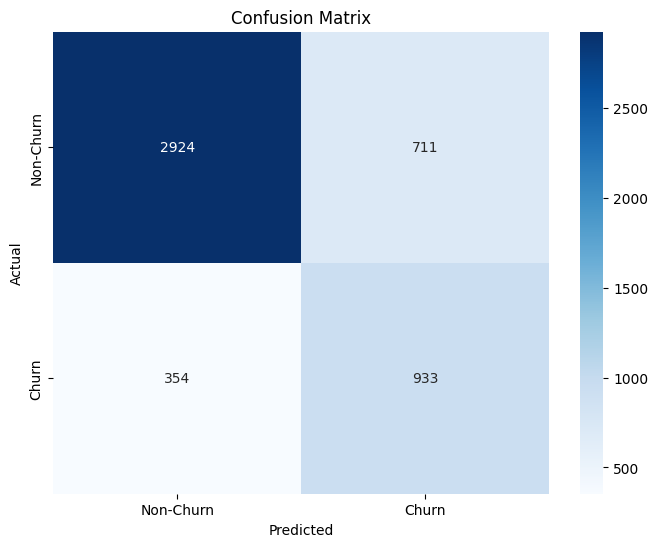

In [130]:
confusion = metrics.confusion_matrix(y_train_pred_final.Churn, y_train_pred_final.predicted)
confusion

# Visualizing the confusion matrix

plt.figure(figsize=(8, 6))
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Churn', 'Churn'], yticklabels=['Non-Churn', 'Churn'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [131]:
print(metrics.classification_report(y_train_pred_final.Churn, y_train_pred_final.predicted))

              precision    recall  f1-score   support

           0       0.89      0.80      0.85      3635
           1       0.57      0.72      0.64      1287

    accuracy                           0.78      4922
   macro avg       0.73      0.76      0.74      4922
weighted avg       0.81      0.78      0.79      4922



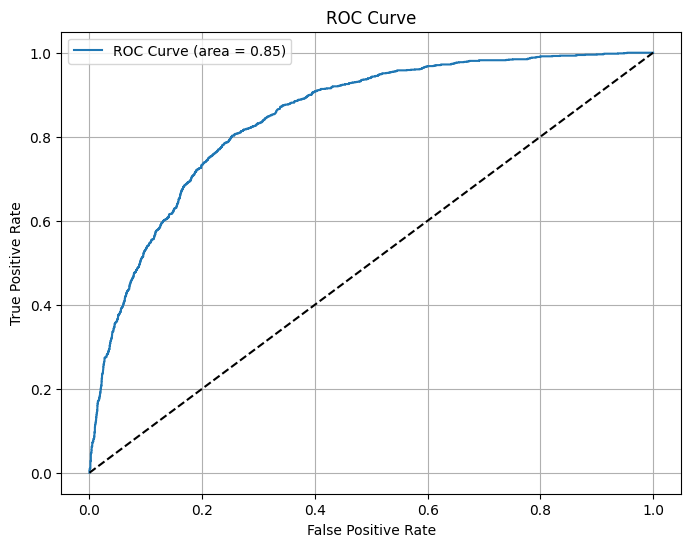

In [132]:
# ROC curve by calculating the values at different cutoffs
plt.figure(figsize=(8, 6))
fpr, tpr, thresholds = metrics.roc_curve(y_train_pred_final.Churn, y_train_pred_final.Churn_Prob, drop_intermediate=False)
plt.plot(fpr, tpr, label='ROC Curve (area = %0.2f)' % metrics.auc(fpr, tpr))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid()
plt.show()

In [133]:
# Let's calculate Accuracy, Sensitivity, and Specificity for various probability cutoffs

# Let's calculate Accuracy, Sensitivity, and Specificity for various probability cutoffs
cutoff_df = pd.DataFrame(columns=['prob', 'accuracy', 'sensi', 'speci'])

# Probability thresholds from 0.0 to 0.9 with step 0.1
numbers = [float(x)/10 for x in range(10)]

for i in numbers:
    # Predict Churn based on current threshold
    y_pred = y_train_pred_final.Churn_Prob.map(lambda x: 1 if x > i else 0)
    cm = metrics.confusion_matrix(y_train_pred_final.Churn, y_pred)
    
    total = sum(sum(cm))
    accuracy = (cm[0,0] + cm[1,1]) / total
    speci = cm[0,0] / (cm[0,0] + cm[0,1])
    sensi = cm[1,1] / (cm[1,0] + cm[1,1])
    
    cutoff_df.loc[i] = [i, accuracy, sensi, speci]

display(cutoff_df)

,prob,accuracy,sensi,speci
0.0,0.0,0.261479,1.000000,0.000000
0.1,0.1,0.608492,0.944833,0.489409
0.2,0.2,0.712922,0.874903,0.655571
0.3,0.3,0.766558,0.783994,0.760385
0.4,0.4,0.792361,0.661228,0.838790
0.5,0.5,0.803738,0.538462,0.897662
0.6,0.6,0.798659,0.376845,0.948006
0.7,0.7,0.768590,0.154623,0.985970
0.8,0.8,0.741162,0.014763,0.998349
0.9,0.9,0.738521,0.000000,1.000000


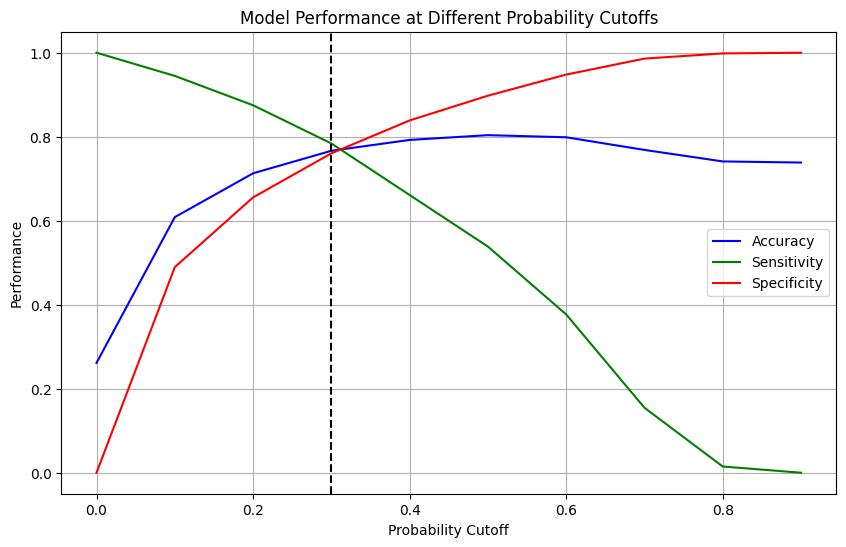

In [134]:
# Plotting Accuracy, Sensitivity and Specificity at different cutoffs
plt.figure(figsize=(10, 6))
plt.plot(cutoff_df['prob'], cutoff_df['accuracy'], label='Accuracy', color='blue')
plt.plot(cutoff_df['prob'], cutoff_df['sensi'], label='Sensitivity', color='green')
plt.plot(cutoff_df['prob'], cutoff_df['speci'], label='Specificity', color='red')
plt.xlabel('Probability Cutoff')
plt.ylabel('Performance')
plt.title('Model Performance at Different Probability Cutoffs')
plt.legend()
plt.grid()
plt.axvline(x=0.3, color='black', linestyle='--', label='Cutoff = 0.3')
plt.show()